# Hand gesture detection with YOLO11n

This standalone Colab notebook fine-tunes a COCO-initialized YOLO11n detector on **all 31,833 images** in the compact HaGRID 30k 384p archive. It predicts 18 gestures and the visible-hand `no_gesture` class from a full RGB frame. Each output contains a label, an original-frame `[x1, y1, x2, y2]` box, and confidence.

**Run order:** select a GPU in Runtime → Change runtime type; run setup and preparation; set `RUN_MODE` to `smoke` for a short end-to-end check, then `full` for training from the original `yolo11n.pt`; use `evaluate` to reload an existing checkpoint. A full run can take hours. Mounting Google Drive keeps checkpoints across runtime restarts. The `last.pt` checkpoint can resume interrupted full training. Do not use test data for model or threshold selection.

Dataset: [cj-mills/hagrid-sample-30k-384p](https://huggingface.co/datasets/cj-mills/hagrid-sample-30k-384p), derived from [HaGRID](https://github.com/hukenovs/hagrid). The compact dataset card lists **CC BY-SA 4.0**; review its terms before redistribution. No face or attendance module is required here.


**Saved execution:** Outputs below are retained from the completed 50-epoch full run, including a resume from epoch 42. The configuration defaults have been reset to `smoke` / `RESUME_FULL=False` for a fresh runtime. Existing outputs show the previous full run until their cells are executed again. Select `full` for a new full experiment or `evaluate` with your checkpoint path to evaluate without training.


## 1. Environment setup

In [1]:
%pip -q install ultralytics==8.4.193


In [2]:
import hashlib, json, os, platform, random, shutil, sys, time, zipfile
from collections import Counter, defaultdict
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import ultralytics
import yaml
from PIL import Image, ImageDraw
from ultralytics import YOLO

print('Python:', platform.python_version(), 'PyTorch:', torch.__version__, 'Ultralytics:', ultralytics.__version__)
print('CUDA:', torch.version.cuda, 'GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none')
assert torch.cuda.is_available(), 'Select a GPU runtime in Colab before training.'
print('Free disk (GiB):', round(shutil.disk_usage('/content').free / 2**30, 2))


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Python: 3.13.16 PyTorch: 2.11.0+cu130 Ultralytics: 8.4.193
CUDA: 13.0 GPU: Tesla T4
Free disk (GiB): 70.05


## 2. Configuration and persistent storage

In [3]:
from google.colab import drive
drive.mount('/content/drive')

ROOT = Path('/content/hand_gesture')
PERSIST = Path('/content/drive/MyDrive/hand_gesture_yolo11n')
PERSIST.mkdir(parents=True, exist_ok=True)
ARCHIVE = ROOT / 'hagrid-sample-30k-384p.zip'
SOURCE_URL = 'https://huggingface.co/datasets/cj-mills/hagrid-sample-30k-384p/resolve/main/hagrid-sample-30k-384p.zip'
ARCHIVE_SHA256 = '575efb79315ee0de1415bbbacb0ded975ad156cb7c43b1538f27a91c29134861'
NAMES = ['call', 'dislike', 'fist', 'four', 'like', 'mute', 'no_gesture', 'ok', 'one', 'palm', 'peace', 'peace_inverted', 'rock', 'stop', 'stop_inverted', 'three', 'three2', 'two_up', 'two_up_inverted']
NAME_TO_ID = {name: i for i, name in enumerate(NAMES)}
SEED = 42
IMGSZ = 640
BATCH = 8  # Reduce to 4 if the smoke run runs out of GPU memory.
EPOCHS = 50
PATIENCE = 10
MATCH_IOU = 0.50
NMS_IOU = 0.70
RUN_MODE = 'smoke'  # 'smoke', 'full', or 'evaluate'
RESUME_FULL = False
UPLOAD_DEMO = False  # Set True to upload an image or video interactively.
WEIGHTS = PERSIST / 'full' / 'weights' / 'best.pt'
DATA = ROOT / 'yolo'
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
PERSIST.mkdir(parents=True, exist_ok=True)
assert len(NAMES) == 19 and len(set(NAMES)) == 19
assert RUN_MODE in {'smoke', 'full', 'evaluate'}
print('Mode:', RUN_MODE, 'Persistent outputs:', PERSIST)


Mounted at /content/drive
Mode: full Persistent outputs: /content/drive/MyDrive/hand_gesture_yolo11n


## 3. Acquire and verify the compact archive

In [4]:
import requests

ROOT.mkdir(parents=True, exist_ok=True)
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as stream:
        for block in iter(lambda: stream.read(8 * 1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

if not ARCHIVE.exists() or sha256_file(ARCHIVE) != ARCHIVE_SHA256:
    temporary = ARCHIVE.with_suffix('.download')
    with requests.get(SOURCE_URL, stream=True, timeout=120) as response:
        response.raise_for_status()
        with open(temporary, 'wb') as output:
            for block in response.iter_content(8 * 1024 * 1024):
                if block:
                    output.write(block)
    assert sha256_file(temporary) == ARCHIVE_SHA256, 'Archive checksum mismatch.'
    temporary.replace(ARCHIVE)
print('Verified archive:', ARCHIVE, ARCHIVE.stat().st_size, 'bytes')

def extract_verified_archive(archive, destination, archive_sha256):
    marker = destination / '.extraction_complete.json'
    if marker.exists() and json.loads(marker.read_text()) == {'sha256': archive_sha256}:
        return
    with zipfile.ZipFile(archive) as z:
        base = destination.resolve()
        for item in z.infolist():
            target = (destination / item.filename).resolve()
            assert target == base or base in target.parents, f'Unsafe ZIP path: {item.filename}'
        assert shutil.disk_usage(destination.parent).free > 3 * 2**30, 'At least 3 GiB free disk is needed for preparation.'
        z.extractall(destination)
    # Write only after extraction succeeds, so an interrupted run is retried.
    marker.write_text(json.dumps({'sha256': archive_sha256}))

EXTRACTED = ROOT / 'source'
extract_verified_archive(ARCHIVE, EXTRACTED, ARCHIVE_SHA256)
SOURCE = EXTRACTED / 'hagrid-sample-30k-384p'


Verified archive: /content/hand_gesture/hagrid-sample-30k-384p.zip 1009688861 bytes


## 4. Audit annotations and reconstruct the subject-disjoint split

In [5]:
annotations = {}
for path in sorted((SOURCE / 'ann_train_val').glob('*.json')):
    with open(path) as stream:
        records = json.load(stream)
    for image_id, record in records.items():
        if image_id in annotations:
            assert annotations[image_id] == record, f'Conflicting annotation: {image_id}'
        annotations[image_id] = record

images = sorted((SOURCE / 'hagrid_30k').glob('train_val_*/*.jpg'))
assert len(images) == 31833, len(images)
manifest = []
box_counts = Counter()
subjects = defaultdict(set)
for image_path in images:
    image_id = image_path.stem
    record = annotations[image_id]
    assert record['user_id'] and len(record['bboxes']) == len(record['labels']) > 0
    split_number = int(hashlib.sha256(f"{SEED}:{record['user_id']}".encode()).hexdigest(), 16) % 100
    split = 'train' if split_number < 80 else 'val' if split_number < 90 else 'test'
    subjects[split].add(record['user_id'])
    for label in record['labels']:
        assert label in NAME_TO_ID, label
        box_counts[(split, label)] += 1
    manifest.append({'image': str(image_path.relative_to(EXTRACTED)).replace('\\', '/'), 'user_id': record['user_id'], 'split': split})
assert not (subjects['train'] & subjects['val'] or subjects['train'] & subjects['test'] or subjects['val'] & subjects['test'])
assert Counter(row['split'] for row in manifest) == {'train': 24997, 'val': 3627, 'test': 3209}
assert sum(box_counts.values()) == 38884
assert all(box_counts[(split, name)] > 0 for split in ('train', 'val', 'test') for name in NAMES)
print('Images:', dict(Counter(row['split'] for row in manifest)))
print('Subjects:', {split: len(ids) for split, ids in subjects.items()})
print('Boxes:', {split: sum(box_counts[(split, name)] for name in NAMES) for split in subjects})
print('Class distribution (train, val, test):')
for name in NAMES:
    print(name, *(box_counts[(split, name)] for split in ('train', 'val', 'test')))


Images: {'val': 3627, 'train': 24997, 'test': 3209}
Subjects: {'val': 862, 'train': 6333, 'test': 778}
Boxes: {'val': 4508, 'train': 30451, 'test': 3925}
Class distribution (train, val, test):
call 1411 184 168
dislike 1432 189 162
fist 1366 199 169
four 1438 195 172
like 1355 184 193
mute 1440 183 188
no_gesture 5455 881 716
ok 1369 209 172
one 1364 220 194
palm 1359 233 178
peace 1382 198 189
peace_inverted 1384 194 164
rock 1319 217 200
stop 1358 205 185
stop_inverted 1429 197 177
three 1392 188 171
three2 1373 199 165
two_up 1449 211 195
two_up_inverted 1376 222 167


## 5. Convert boxes to YOLO format

In [6]:
def convert_box(box):
    x, y, w, h = map(float, box)
    assert all(np.isfinite([x, y, w, h])) and w > 0 and h > 0
    x1, y1 = max(0., min(1., x)), max(0., min(1., y))
    x2, y2 = max(0., min(1., x + w)), max(0., min(1., y + h))
    assert x2 > x1 and y2 > y1, f'Invalid clipped box: {box}'
    return ((x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1), (x1, y1, x2, y2) != (x, y, x + w, y + h)

assert convert_box([0.76, 0.88, 0.095, 0.121])[1]
assert np.allclose(convert_box([0.1, 0.2, 0.4, 0.5])[0], [0.3, 0.45, 0.4, 0.5])

MARKER = DATA / '.prepared.json'
expected_marker = {'archive_sha256': ARCHIVE_SHA256, 'seed': SEED, 'classes': NAMES, 'images': len(images)}
if not MARKER.exists() or json.loads(MARKER.read_text()) != expected_marker:
    if DATA.exists():
        shutil.rmtree(DATA)
    corrections = []
    for row in manifest:
        src = EXTRACTED / row['image']
        split = row['split']
        dst_image = DATA / 'images' / split / src.name
        dst_label = DATA / 'labels' / split / (src.stem + '.txt')
        dst_image.parent.mkdir(parents=True, exist_ok=True)
        dst_label.parent.mkdir(parents=True, exist_ok=True)
        lines = []
        record = annotations[src.stem]
        for box, label in zip(record['bboxes'], record['labels']):
            converted, clipped = convert_box(box)
            if clipped:
                corrections.append({'image_id': src.stem, 'label': label, 'original_box': box})
            lines.append(f"{NAME_TO_ID[label]} " + ' '.join(f'{value:.8f}' for value in converted))
        dst_label.write_text('\n'.join(lines) + '\n')
        shutil.copy2(src, dst_image)
    assert len(corrections) == 1 and corrections[0]['image_id'] == '1d82b4f0-6f84-40f8-acbf-10f05d8fe5b0'
    (PERSIST / 'coordinate_corrections.json').write_text(json.dumps(corrections, indent=2))
    MARKER.write_text(json.dumps(expected_marker))
else:
    print('Reusing verified prepared dataset marker.')

dataset_yaml = {'path': str(DATA), 'train': 'images/train', 'val': 'images/val', 'test': 'images/test', 'names': dict(enumerate(NAMES))}
(DATA / 'data.yaml').write_text(yaml.safe_dump(dataset_yaml, sort_keys=False))
(PERSIST / 'data.yaml').write_text(yaml.safe_dump(dataset_yaml, sort_keys=False))
(PERSIST / 'class_names.json').write_text(json.dumps(NAMES, indent=2))
(PERSIST / 'split_manifest.json').write_text(json.dumps(manifest))
for split, count in [('train', 24997), ('val', 3627), ('test', 3209)]:
    assert len(list((DATA / 'images' / split).glob('*.jpg'))) == count
    assert len(list((DATA / 'labels' / split).glob('*.txt'))) == count
print('YOLO dataset:', DATA / 'data.yaml')


YOLO dataset: /content/hand_gesture/yolo/data.yaml


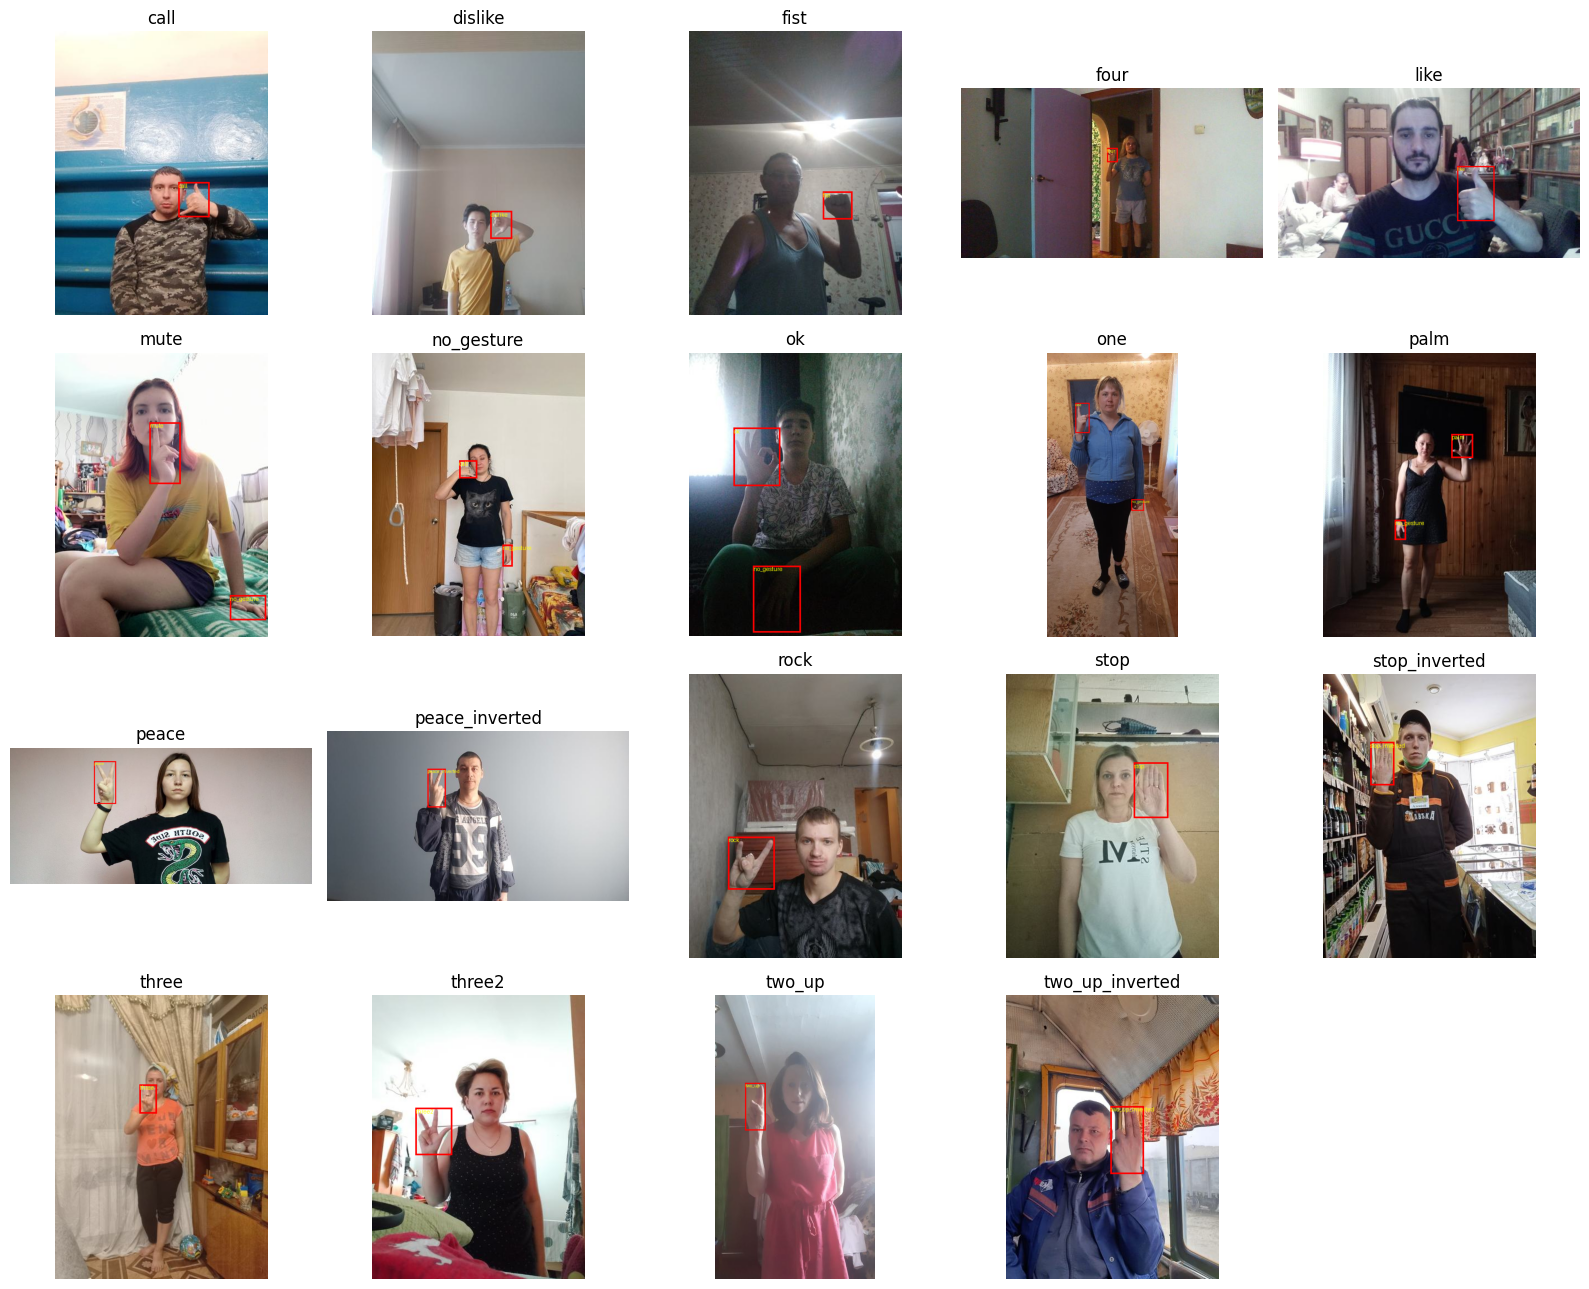

Images with multiple hands: 7051


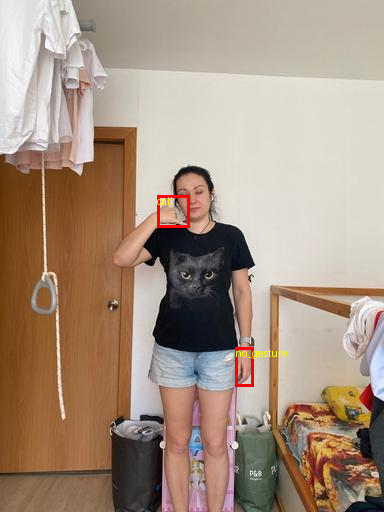

In [7]:
fig, axes = plt.subplots(4, 5, figsize=(16, 13))
for ax, name in zip(axes.flat, NAMES):
    row = next(row for row in manifest if row['split'] == 'train' and name in annotations[Path(row['image']).stem]['labels'])
    path = EXTRACTED / row['image']
    image = Image.open(path).convert('RGB')
    draw = ImageDraw.Draw(image)
    for box, label in zip(annotations[path.stem]['bboxes'], annotations[path.stem]['labels']):
        cx, cy, w, h = convert_box(box)[0]
        draw.rectangle([(cx - w/2) * image.width, (cy - h/2) * image.height, (cx + w/2) * image.width, (cy + h/2) * image.height], outline='red', width=3)
        draw.text(((cx - w/2) * image.width, (cy - h/2) * image.height), label, fill='yellow')
    ax.imshow(image)
    ax.set_title(name)
    ax.axis('off')
for ax in list(axes.flat)[len(NAMES):]:
    ax.axis('off')
plt.tight_layout()
plt.show()
print('Images with multiple hands:', sum(len(annotations[Path(row['image']).stem]['bboxes']) > 1 for row in manifest))
multi = next(row for row in manifest if len(annotations[Path(row['image']).stem]['bboxes']) > 1)
multi_path = EXTRACTED / multi['image']
multi_image = Image.open(multi_path).convert('RGB')
pen = ImageDraw.Draw(multi_image)
for box, label in zip(annotations[multi_path.stem]['bboxes'], annotations[multi_path.stem]['labels']):
    cx, cy, w, h = convert_box(box)[0]
    pen.rectangle([(cx-w/2)*multi_image.width, (cy-h/2)*multi_image.height,
                   (cx+w/2)*multi_image.width, (cy+h/2)*multi_image.height], outline='red', width=3)
    pen.text(((cx-w/2)*multi_image.width, (cy-h/2)*multi_image.height), label, fill='yellow')
display(multi_image)


## 6. Smoke test or full fine-tuning

The smoke run uses a small subject-disjoint subset and never uses test data. After it works, set `RUN_MODE='full'` and rerun from configuration onward. The full run creates a new YOLO11n instance from COCO weights. Ultralytics selects `best.pt` using its detection fitness, based on validation mAP50-95; `last.pt` is available for resumption. Checkpoints are written to Google Drive each epoch.

In [8]:
SMOKE = ROOT / 'smoke'
if RUN_MODE == 'smoke':
    if SMOKE.exists():
        shutil.rmtree(SMOKE)
    for split, per_class in [('train', 30), ('val', 8)]:
        chosen = set()
        for name in NAMES:
            candidates = [row for row in manifest if row['split'] == split and name in annotations[Path(row['image']).stem]['labels']]
            chosen.update(Path(row['image']).stem for row in candidates[:per_class])
        for image_id in chosen:
            src_image = DATA / 'images' / split / f'{image_id}.jpg'
            src_label = DATA / 'labels' / split / f'{image_id}.txt'
            for source, kind in [(src_image, 'images'), (src_label, 'labels')]:
                destination = SMOKE / kind / split / source.name
                destination.parent.mkdir(parents=True, exist_ok=True)
                shutil.copy2(source, destination)
    smoke_yaml = {'path': str(SMOKE), 'train': 'images/train', 'val': 'images/val', 'names': dict(enumerate(NAMES))}
    (SMOKE / 'data.yaml').write_text(yaml.safe_dump(smoke_yaml, sort_keys=False))
    print('Smoke images:', {s: len(list((SMOKE / 'images' / s).glob('*.jpg'))) for s in ['train', 'val']})


In [9]:
if RUN_MODE in {'smoke', 'full'}:
    project_name = 'smoke' if RUN_MODE == 'smoke' else 'full'
    run_dir = PERSIST / project_name
    last = run_dir / 'weights' / 'last.pt'
    assert not (RUN_MODE == 'smoke' and RESUME_FULL)
    if RUN_MODE == 'full' and RESUME_FULL:
        assert last.exists(), f'No resumable checkpoint at {last}'
    if RUN_MODE == 'full' and last.exists() and not RESUME_FULL:
        raise RuntimeError('Full checkpoint exists. Set RESUME_FULL=True to resume, or move the old run directory before starting fresh.')
    model = YOLO(str(last) if RESUME_FULL and RUN_MODE == 'full' else 'yolo11n.pt')
    started = time.time()
    model.train(data=str((SMOKE if RUN_MODE == 'smoke' else DATA) / 'data.yaml'),
                epochs=2 if RUN_MODE == 'smoke' else EPOCHS, imgsz=IMGSZ,
                batch=BATCH, patience=PATIENCE, seed=SEED, device=0, amp=True,
                optimizer='auto', fliplr=0.5, flipud=0.0, degrees=0.0,
                project=str(PERSIST), name=project_name, exist_ok=True,
                save=True, resume=RESUME_FULL and RUN_MODE == 'full')
    training_config = {
        'resolved_training_arguments': vars(model.trainer.args),
        'python': platform.python_version(), 'torch': torch.__version__,
        'ultralytics': ultralytics.__version__, 'gpu': torch.cuda.get_device_name(0),
        'source': SOURCE_URL, 'archive_sha256': ARCHIVE_SHA256,
    }
    (run_dir / 'run_config.json').write_text(json.dumps(training_config, indent=2, default=str))
    print('Training minutes:', round((time.time() - started) / 60, 1))
    print('Peak GPU memory (GiB):', round(torch.cuda.max_memory_allocated() / 2**30, 2))
    checkpoint = run_dir / 'weights' / 'best.pt'
    assert checkpoint.exists() and last.exists()
    assert len(YOLO(str(checkpoint)).names) == 19
    sample = next((DATA / 'images' / 'val').glob('*.jpg'))
    print('Reloaded checkpoint inference:', len(YOLO(str(checkpoint)).predict(str(sample), verbose=False)[0].boxes))
else:
    checkpoint = WEIGHTS
    assert checkpoint.exists(), f'Missing trained checkpoint: {checkpoint}'


New https://pypi.org/project/ultralytics/8.4.194 available 😃 Update with 'pip install -U ultralytics'
WARNING ⚠️ Resume ignores ['optimizer'], using checkpoint values. Start a new run to change them.
Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/hand_gesture/yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_widt

## 7. Operating-point evaluation

Predictions are obtained with low confidence (0.05) and NMS IoU 0.70. Ground truth and predictions are matched by descending box IoU at 0.50, independently of class. Wrong-class matches count as both a false positive and a false negative. The 20th confusion category is background/no match, distinct from `no_gesture`. Validation chooses the confidence threshold; test is evaluated once at that fixed threshold.

In [10]:
def box_iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    intersection = max(0., x2-x1) * max(0., y2-y1)
    area_a = max(0., a[2]-a[0]) * max(0., a[3]-a[1])
    area_b = max(0., b[2]-b[0]) * max(0., b[3]-b[1])
    return intersection / (area_a + area_b - intersection) if area_a + area_b > intersection else 0.

def ground_truth(label_path, image_width, image_height):
    objects = []
    for line in label_path.read_text().splitlines():
        cls, cx, cy, w, h = map(float, line.split())
        assert int(cls) == cls and 0 <= cls < 19 and w > 0 and h > 0
        objects.append((int(cls), [(cx-w/2)*image_width, (cy-h/2)*image_height,
                                    (cx+w/2)*image_width, (cy+h/2)*image_height]))
    return objects

def confusion_for_image(truth, predicted, threshold, match_iou=MATCH_IOU):
    predicted = [item for item in predicted if item[2] >= threshold]
    matrix = np.zeros((20, 20), dtype=np.int64)
    pairs = []
    for gi, (_, gt_box) in enumerate(truth):
        for pi, (_, pred_box, _) in enumerate(predicted):
            overlap = box_iou(gt_box, pred_box)
            if overlap >= match_iou:
                pairs.append((-overlap, gi, pi))
    matched_gt, matched_pred = set(), set()
    for _, gi, pi in sorted(pairs):
        if gi not in matched_gt and pi not in matched_pred:
            matrix[truth[gi][0], predicted[pi][0]] += 1
            matched_gt.add(gi)
            matched_pred.add(pi)
    for gi, (cls, _) in enumerate(truth):
        if gi not in matched_gt:
            matrix[cls, 19] += 1
    for pi, (cls, _, _) in enumerate(predicted):
        if pi not in matched_pred:
            matrix[19, cls] += 1
    return matrix

unit = [0, 0, 10, 10]
assert confusion_for_image([], [], .5).sum() == 0
assert confusion_for_image([(1, unit)], [(1, unit, .9)], .5)[1, 1] == 1
duplicate = confusion_for_image([(1, unit)], [(1, unit, .9), (1, unit, .8)], .5)
assert duplicate[1, 1] == 1 and duplicate[19, 1] == 1
wrong = confusion_for_image([(1, unit)], [(2, unit, .9)], .5)
assert wrong[1, 2] == 1
print('Evaluator checks passed.')


Evaluator checks passed.


In [11]:
def collect_predictions(split, model, output_path):
    metadata_path = output_path.with_suffix('.metadata.json')
    cache_metadata = {'checkpoint_sha256': sha256_file(checkpoint), 'split': split,
                      'image_size': IMGSZ, 'nms_iou': NMS_IOU, 'minimum_confidence': 0.05}
    if output_path.exists() and metadata_path.exists() and json.loads(metadata_path.read_text()) == cache_metadata:
        return json.loads(output_path.read_text())
    records = []
    paths = sorted((DATA / 'images' / split).glob('*.jpg'))
    for index, path in enumerate(paths):
        result = model.predict(str(path), conf=0.05, iou=NMS_IOU, imgsz=IMGSZ, verbose=False)[0]
        height, width = result.orig_shape
        predictions = [(int(box.cls.item()), [float(x) for x in box.xyxy[0].tolist()], float(box.conf.item())) for box in result.boxes]
        records.append({'image': path.name, 'height': height, 'width': width, 'predictions': predictions})
        if (index + 1) % 500 == 0:
            print(split, index + 1, '/', len(paths))
    output_path.write_text(json.dumps(records))
    metadata_path.write_text(json.dumps(cache_metadata))
    return records

def evaluate_records(records, split, threshold):
    matrix = np.zeros((20, 20), dtype=np.int64)
    for row in records:
        truth = ground_truth(DATA / 'labels' / split / Path(row['image']).with_suffix('.txt'), row['width'], row['height'])
        matrix += confusion_for_image(truth, row['predictions'], threshold)
    return matrix

def score_matrix(matrix):
    tp = np.diag(matrix)[:19]
    support = matrix[:19, :].sum(axis=1)
    fp = matrix[:, :19].sum(axis=0) - tp
    fn = support - tp
    precision = np.divide(tp, tp+fp, out=np.zeros(19), where=(tp+fp)>0)
    recall = np.divide(tp, tp+fn, out=np.zeros(19), where=(tp+fn)>0)
    f1 = np.divide(2*precision*recall, precision+recall, out=np.zeros(19), where=(precision+recall)>0)
    return {'precision': precision, 'recall': recall, 'f1': f1, 'support': support}

if RUN_MODE != 'smoke':
    model = YOLO(str(checkpoint))
    assert list(model.names.values()) == NAMES
    val_records = collect_predictions('val', model, PERSIST / 'val_predictions_lowconf.json')
    thresholds = np.arange(0.05, 1., 0.05)
    candidates = [(float(score_matrix(evaluate_records(val_records, 'val', float(t)))['f1'].mean()), float(t)) for t in thresholds]
    selected_f1, confidence = max(candidates)
    settings = {'confidence': confidence, 'matching_iou': MATCH_IOU, 'nms_iou': NMS_IOU,
                'image_size': IMGSZ, 'validation_macro_f1': selected_f1,
                'checkpoint': str(checkpoint), 'checkpoint_sha256': sha256_file(checkpoint), 'ultralytics': ultralytics.__version__}
    (PERSIST / 'evaluation_settings.json').write_text(json.dumps(settings, indent=2))
    print('Validation-selected confidence:', confidence, 'macro F1:', round(selected_f1, 4))


val 500 / 3627
val 1000 / 3627
val 1500 / 3627
val 2000 / 3627
val 2500 / 3627
val 3000 / 3627
val 3500 / 3627
Validation-selected confidence: 0.6000000000000001 macro F1: 0.9881


test 500 / 3209
test 1000 / 3209
test 1500 / 3209
test 2000 / 3209
test 2500 / 3209
test 3000 / 3209
19-class macro: {'precision': 0.9882005561307483, 'recall': 0.9859327373864119, 'f1': 0.9870266323615277}
18-gesture macro: {'precision': 0.9914808473962622, 'recall': 0.9877893357700765, 'f1': 0.989600908872034}
Per-class scores: [
  {
    "class": "call",
    "precision": 0.9822485207100592,
    "recall": 0.9880952380952381,
    "f1": 0.9851632047477745,
    "support": 168.0
  },
  {
    "class": "dislike",
    "precision": 1.0,
    "recall": 0.9876543209876543,
    "f1": 0.9937888198757764,
    "support": 162.0
  },
  {
    "class": "fist",
    "precision": 1.0,
    "recall": 0.9940828402366864,
    "f1": 0.9970326409495549,
    "support": 169.0
  },
  {
    "class": "four",
    "precision": 1.0,
    "recall": 0.9941860465116279,
    "f1": 0.9970845481049563,
    "support": 172.0
  },
  {
    "class": "like",
    "precision": 0.9895287958115183,
    "recall": 0.9792746113989638,
    

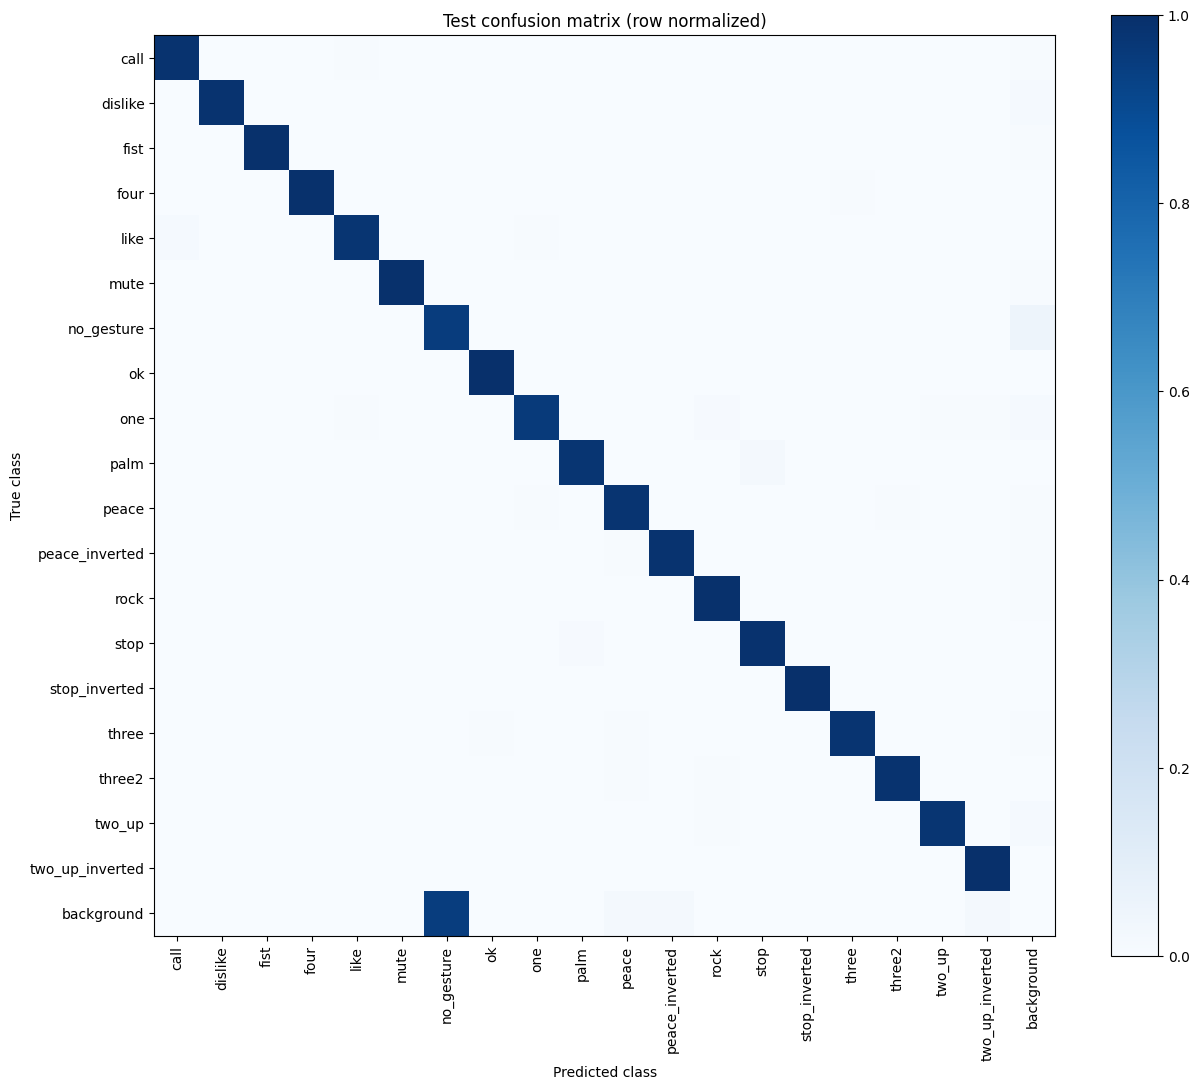

In [12]:
if RUN_MODE != 'smoke':
    test_records = collect_predictions('test', model, PERSIST / 'test_predictions_lowconf.json')
    matrix = evaluate_records(test_records, 'test', confidence)
    scores = score_matrix(matrix)
    rows = []
    for i, name in enumerate(NAMES):
        rows.append({'class': name, **{key: float(value[i]) for key, value in scores.items()}})
    macro = {key: float(scores[key].mean()) for key in ('precision', 'recall', 'f1')}
    gesture_macro = {key: float(np.delete(scores[key], NAME_TO_ID['no_gesture']).mean()) for key in ('precision', 'recall', 'f1')}
    results = {'per_class': rows, 'macro_19': macro, 'macro_18_gestures': gesture_macro,
               'confidence': confidence, 'matching_iou': MATCH_IOU, 'nms_iou': NMS_IOU}
    (PERSIST / 'test_metrics.json').write_text(json.dumps(results, indent=2))
    np.savetxt(PERSIST / 'confusion_raw.csv', matrix, fmt='%d', delimiter=',')
    normalized = np.divide(matrix, matrix.sum(axis=1, keepdims=True), out=np.zeros_like(matrix, dtype=float), where=matrix.sum(axis=1, keepdims=True)>0)
    np.savetxt(PERSIST / 'confusion_normalized.csv', normalized, fmt='%.6f', delimiter=',')
    print('19-class macro:', macro)
    print('18-gesture macro:', gesture_macro)
    print('Per-class scores:', json.dumps(rows, indent=2))
    fig, ax = plt.subplots(figsize=(13, 11))
    im = ax.imshow(normalized, vmin=0, vmax=1, cmap='Blues')
    labels = NAMES + ['background']
    ax.set(xticks=range(20), yticks=range(20), xticklabels=labels, yticklabels=labels,
           xlabel='Predicted class', ylabel='True class', title='Test confusion matrix (row normalized)')
    plt.setp(ax.get_xticklabels(), rotation=90)
    fig.colorbar(im, ax=ax)
    fig.tight_layout()
    fig.savefig(PERSIST / 'confusion_normalized.png', dpi=150)
    plt.show()


## 8. Full-frame image and video inference

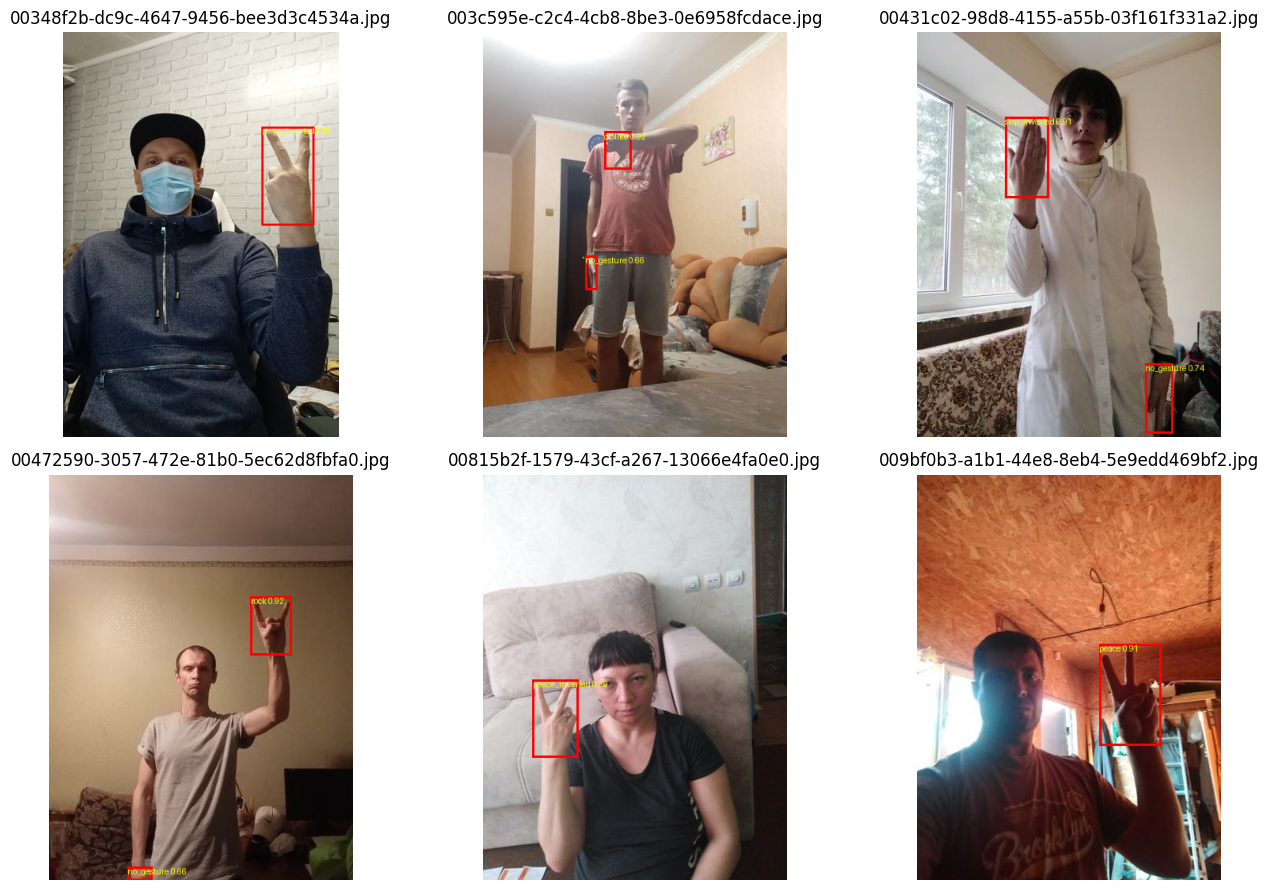

In [13]:
def detect_rgb(frame_rgb, detector, confidence_threshold):
    assert isinstance(frame_rgb, np.ndarray) and frame_rgb.ndim == 3 and frame_rgb.shape[2] == 3
    assert frame_rgb.dtype == np.uint8
    # PIL preserves RGB semantics; Ultralytics returns boxes in original-image coordinates.
    result = detector.predict(Image.fromarray(frame_rgb), conf=confidence_threshold,
                              iou=NMS_IOU, imgsz=IMGSZ, verbose=False)[0]
    height, width = frame_rgb.shape[:2]
    detections = []
    for box in result.boxes:
        xyxy = [float(v) for v in box.xyxy[0].tolist()]
        xyxy = [max(0., min(float(width if i % 2 == 0 else height), v)) for i, v in enumerate(xyxy)]
        detections.append({'label': NAMES[int(box.cls.item())], 'bbox': xyxy,
                           'confidence': float(box.conf.item())})
    return detections

def draw_detections(frame_rgb, detections):
    output = Image.fromarray(frame_rgb)
    pen = ImageDraw.Draw(output)
    for item in detections:
        pen.rectangle(item['bbox'], outline='red', width=3)
        pen.text(item['bbox'][:2], f"{item['label']} {item['confidence']:.2f}", fill='yellow')
    return output

if RUN_MODE != 'smoke':
    example_paths = list(sorted((DATA / 'images' / 'test').glob('*.jpg')))[:6]
    fig, axes = plt.subplots(2, 3, figsize=(14, 9))
    for ax, path in zip(axes.flat, example_paths):
        image = np.asarray(Image.open(path).convert('RGB'))
        detections = detect_rgb(image, model, confidence)
        ax.imshow(draw_detections(image, detections))
        ax.set_title(path.name)
        ax.axis('off')
    plt.tight_layout()
    plt.savefig(PERSIST / 'inference_examples.png', dpi=150)
    plt.show()


In [14]:
# Optional: upload an image or video to demonstrate full-frame inference.
from google.colab import files
if RUN_MODE != 'smoke' and UPLOAD_DEMO:
    uploaded = files.upload()
    for filename, contents in uploaded.items():
        input_path = ROOT / Path(filename).name
        input_path.write_bytes(contents)
        if input_path.suffix.lower() in {'.jpg', '.jpeg', '.png', '.webp'}:
            frame = np.asarray(Image.open(input_path).convert('RGB'))
            detections = detect_rgb(frame, model, confidence)
            display(draw_detections(frame, detections))
            (PERSIST / f'{input_path.stem}_predictions.json').write_text(json.dumps(detections, indent=2))
        elif input_path.suffix.lower() in {'.mp4', '.mov', '.avi'}:
            capture = cv2.VideoCapture(str(input_path))
            assert capture.isOpened(), f'Cannot open video: {filename}'
            fps = capture.get(cv2.CAP_PROP_FPS) or 25
            width = int(capture.get(cv2.CAP_PROP_FRAME_WIDTH))
            height = int(capture.get(cv2.CAP_PROP_FRAME_HEIGHT))
            output_path = PERSIST / f'{input_path.stem}_annotated.mp4'
            writer = cv2.VideoWriter(str(output_path), cv2.VideoWriter_fourcc(*'mp4v'), fps, (width, height))
            assert writer.isOpened(), 'Cannot create output video.'
            frame_predictions = []
            try:
                index = 0
                while True:
                    ok, bgr = capture.read()
                    if not ok:
                        break
                    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
                    detections = detect_rgb(rgb, model, confidence)
                    annotated = np.asarray(draw_detections(rgb, detections))
                    writer.write(cv2.cvtColor(annotated, cv2.COLOR_RGB2BGR))
                    frame_predictions.append({'frame': index, 'detections': detections})
                    index += 1
            finally:
                capture.release()
                writer.release()
            (PERSIST / f'{input_path.stem}_video_predictions.json').write_text(json.dumps(frame_predictions))
            print('Saved:', output_path, 'frames:', index)


## 9. Error analysis and export

Review `test_metrics.json`, the confusion matrix, and the examples. Pay particular attention to similar finger poses, small or dark hands, occlusion, and frames without a visible hand. The compact dataset contains no confirmed empty-frame benchmark; `no_gesture` means a visible natural hand. The model does not associate gestures with people or trigger attendance actions. Report measured values only after the full Colab run.

Top error examples: [(2, '8b98f698-a4ff-4620-a2d7-41eb1f1ca35e.jpg'), (2, '29fc9f63-1cb9-4d05-b229-f30f4c168150.jpg'), (1, 'fe482e22-9503-4dd1-bfb5-eae2034e97ff.jpg'), (1, 'fb4819ee-0ccc-40f8-832f-c0738ec0b15e.jpg'), (1, 'fa8f6950-7f6d-4314-8c0e-d3f8ba499e2a.jpg'), (1, 'f9c34a17-5f5d-4210-b372-5ff5ee068e31.jpg'), (1, 'f9953bf1-705c-404e-8e1a-c7403f093ae5.jpg'), (1, 'f8b482da-cd62-48ee-b447-95b01951575a.jpg'), (1, 'f88a4f21-274a-4348-8799-8c4776e8234c.jpg'), (1, 'f7cb6589-29cc-401f-a40f-5479c64cdce3.jpg')]


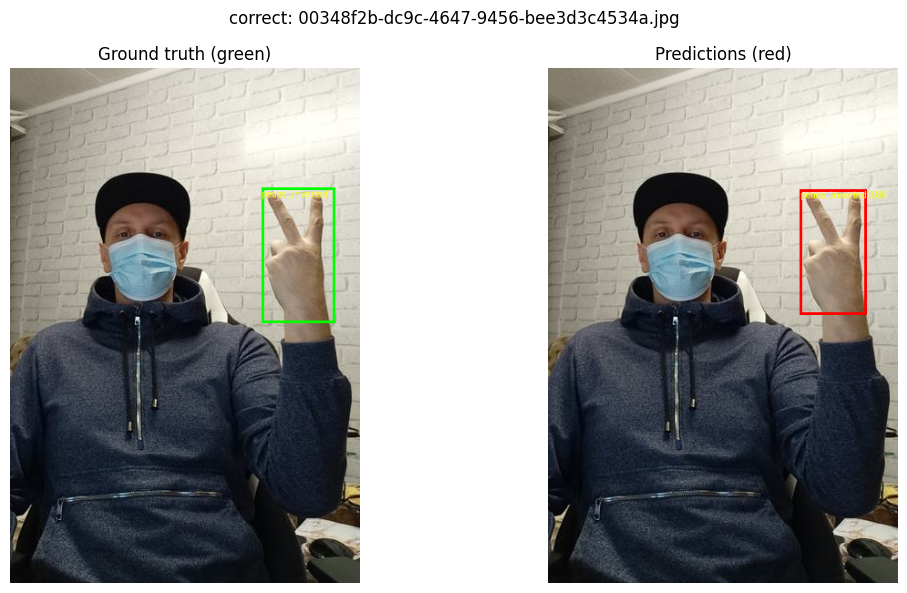

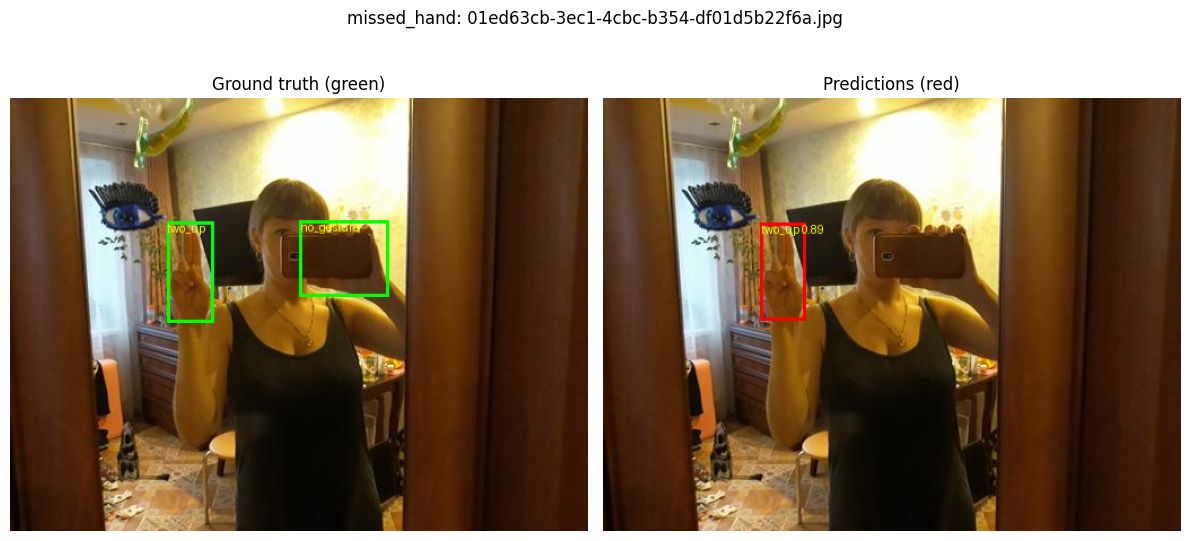

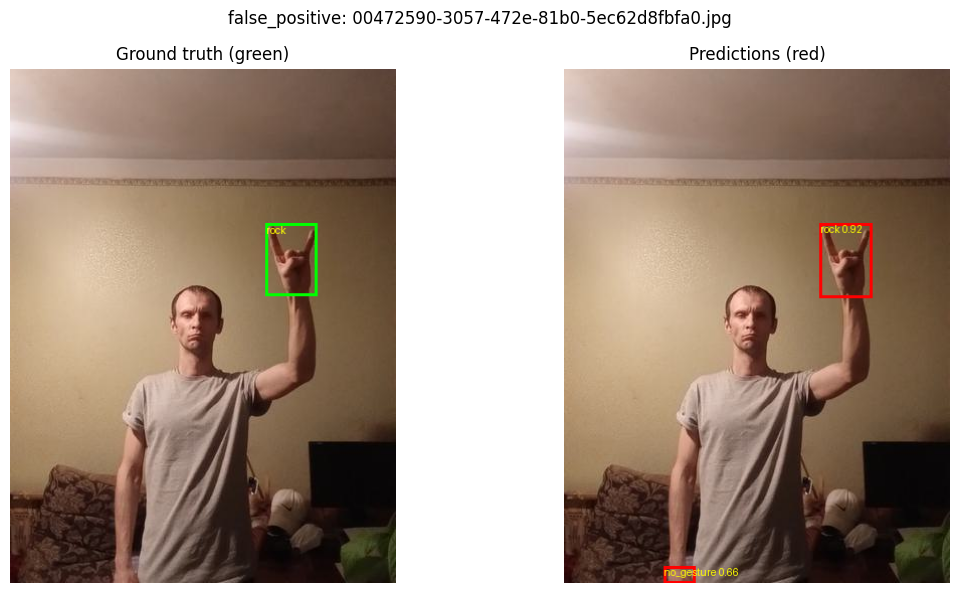

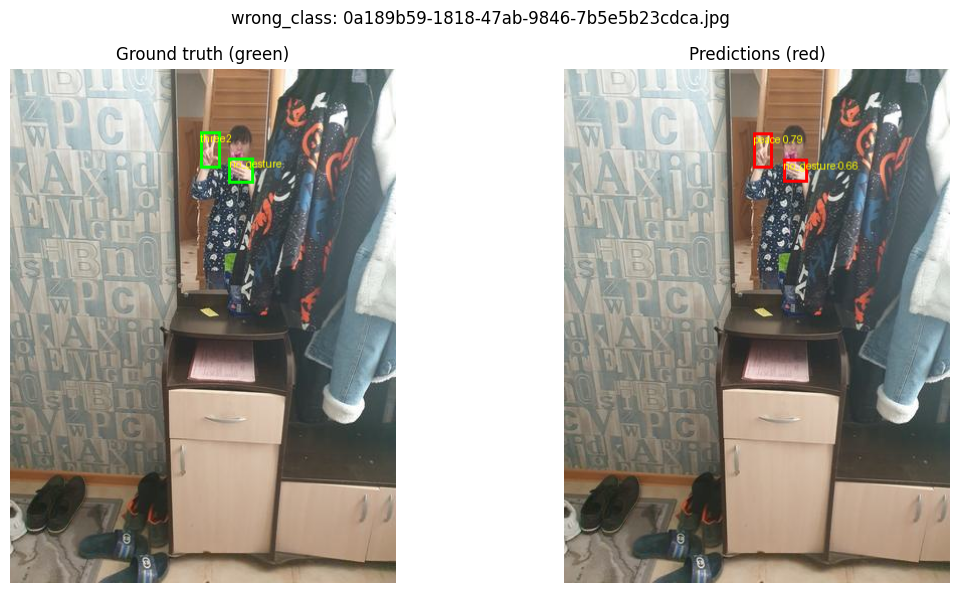

Persistent artifacts: /content/drive/MyDrive/hand_gesture_yolo11n Export archive: /content/hand_gesture/hand_gesture_artifacts.zip


In [15]:
def example_categories(matrix):
    classes = matrix[:19, :19]
    return {
        'correct': bool(np.trace(classes)),
        'missed_hand': bool(matrix[:19, 19].sum()),
        'false_positive': bool(matrix[19, :19].sum()),
        'wrong_class': bool(classes.sum() - np.trace(classes)),
    }

def export_evaluated_checkpoint(checkpoint, output_dir, detector):
    exported = output_dir / 'evaluated_best.pt'
    if checkpoint.resolve() != exported.resolve():
        shutil.copy2(checkpoint, exported)
    checksum = sha256_file(exported)
    assert checksum == sha256_file(checkpoint)
    metadata = {
        'checkpoint': exported.name, 'checkpoint_sha256': checksum,
        'original_checkpoint': str(checkpoint),
        'training_arguments_source': 'checkpoint train_args',
        'training_arguments': (detector.ckpt or {}).get('train_args'),
    }
    (output_dir / 'evaluated_checkpoint_config.json').write_text(json.dumps(metadata, indent=2, default=str))
    return exported, checksum

if RUN_MODE != 'smoke':
    errors, examples = [], {}
    for row in test_records:
        truth = ground_truth(DATA / 'labels' / 'test' / Path(row['image']).with_suffix('.txt'), row['width'], row['height'])
        local_matrix = confusion_for_image(truth, row['predictions'], confidence)
        wrong = int(local_matrix.sum() - np.trace(local_matrix[:19, :19]))
        if wrong:
            errors.append((wrong, row['image']))
        for category, present in example_categories(local_matrix).items():
            if present and category not in examples:
                examples[category] = row
    print('Top error examples:', sorted(errors, reverse=True)[:10])
    for category in ('correct', 'missed_hand', 'false_positive', 'wrong_class'):
        if category not in examples:
            print('No test example found for:', category)
            continue
        row = examples[category]
        image = np.asarray(Image.open(DATA / 'images' / 'test' / row['image']).convert('RGB'))
        truth = ground_truth(DATA / 'labels' / 'test' / Path(row['image']).with_suffix('.txt'), row['width'], row['height'])
        ground_image = Image.fromarray(image)
        pen = ImageDraw.Draw(ground_image)
        for class_id, box in truth:
            pen.rectangle(box, outline='lime', width=3)
            pen.text(box[:2], NAMES[class_id], fill='yellow')
        detections = [{'label': NAMES[int(cls)], 'bbox': box, 'confidence': score}
                      for cls, box, score in row['predictions'] if score >= confidence]
        fig, axes = plt.subplots(1, 2, figsize=(12, 6))
        axes[0].imshow(ground_image)
        axes[0].set_title('Ground truth (green)')
        axes[1].imshow(draw_detections(image, detections))
        axes[1].set_title('Predictions (red)')
        for ax in axes:
            ax.axis('off')
        fig.suptitle(f"{category}: {row['image']}")
        fig.tight_layout()
        fig.savefig(PERSIST / f'error_analysis_{category}.png', dpi=150)
        plt.show()
        plt.close(fig)
    (PERSIST / 'error_examples.json').write_text(json.dumps(examples, indent=2))

    exported_checkpoint, exported_sha256 = export_evaluated_checkpoint(checkpoint, PERSIST, model)
    README = f'''# Hand gesture YOLO11n artifacts

Source: {SOURCE_URL}
Archive SHA256: {ARCHIVE_SHA256}
Classes: {', '.join(NAMES)}
Input: one full RGB image/frame. Output: label, original-frame xyxy box, confidence.
Evaluated checkpoint: {exported_checkpoint.name}
Checkpoint SHA256: {exported_sha256}
Checkpoint training arguments: evaluated_checkpoint_config.json (null if unavailable).
Local training runs retain their actual configuration in full/run_config.json.
The local full/weights/last.pt, when present, resumes that local training run.
Validation-selected confidence: {confidence:.2f}; matching IoU: {MATCH_IOU}; NMS IoU: {NMS_IOU}.
Reload with `YOLO("{exported_checkpoint.name}")`. Use the notebook's `detect_rgb` helper.
The benchmark uses subject-disjoint train/val/test splits; no empty-frame benchmark is included.
'''
    (PERSIST / 'README.md').write_text(README)
    evaluation_session = {
        'run_mode': RUN_MODE, 'settings': settings, 'python': platform.python_version(),
        'torch': torch.__version__, 'ultralytics': ultralytics.__version__,
        'gpu': torch.cuda.get_device_name(0),
    }
    (PERSIST / 'evaluation_session.json').write_text(json.dumps(evaluation_session, indent=2))
    old_export = PERSIST / 'hand_gesture_artifacts.zip'
    if old_export.exists():
        old_export.unlink()
    archive_path = shutil.make_archive(str(ROOT / 'hand_gesture_artifacts'), 'zip', PERSIST)
    shutil.copy2(archive_path, PERSIST / 'hand_gesture_artifacts.zip')
    print('Persistent artifacts:', PERSIST, 'Export archive:', archive_path)
